# 11. Image Segmentation: U-Net on ISPRS Vaihingen

This notebook does **semantic segmentation of aerial images**: it labels every pixel as one of six land-cover classes (impervious surfaces, building, low vegetation, tree, car, clutter). It trains a U-Net from scratch on the ISPRS Vaihingen benchmark, in the mmsegmentation `img_dir/ann_dir` format published on Kaggle.

> **What changed from the first version.** The first version thresholded the masks with `mask > 127`, as if they were black-and-white images. These masks actually store **class IDs (0–6)**, so the threshold removed every label. The model was trained on empty targets and only ever predicted background. That is why it reported 99.98% pixel accuracy with a Dice score of exactly 0. This version uses the class IDs correctly, resizes masks with nearest-neighbour instead of bilinear interpolation, splits the data by geographic area, and reports the benchmark's standard metrics (per-class IoU / F1, mIoU) rather than pixel accuracy alone.

## 1. Setup

In [1]:
import random
import time
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

Device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 2. Data
In the label PNGs, **0 marks object boundaries**. The benchmark excludes these from scoring, so here they are ignored in both training and evaluation. Values **1–6** are the classes. The official `val` split covers 17 geographic areas that never appear in `train`, so it serves as the **test set**. Three of the 16 training areas are held out for validation (model selection). Splitting by area rather than by tile keeps neighbouring tiles of the same area from ending up on both sides of a split.

In [2]:
img_root = Path(kagglehub.dataset_download("pushkar007/vaihingendataimg")) / "img_dir"
ann_root = Path(kagglehub.dataset_download("pushkar007/vaihingendataann")) / "ann_dir"

CLASSES = ["Impervious surfaces", "Building", "Low vegetation", "Tree", "Car", "Clutter"]
IGNORE = 255
PALETTE = np.array([[255, 255, 255], [0, 0, 255], [0, 255, 255], [0, 255, 0], [255, 255, 0], [255, 0, 0]], np.uint8)  # ISPRS colours

def load_split(split):
    names = sorted({p.name for p in (img_root / split).glob("*.png")} & {p.name for p in (ann_root / split).glob("*.png")})
    imgs = np.stack([np.asarray(Image.open(img_root / split / n).convert("RGB")) for n in names])
    raw = np.stack([np.asarray(Image.open(ann_root / split / n)) for n in names])
    labels = np.where(raw == 0, IGNORE, raw - 1).astype(np.uint8)  # 0 = boundary -> ignore; 1..6 -> classes 0..5
    areas = np.array([n.split("_")[0] for n in names])
    return names, imgs, labels, areas

_, train_imgs, train_lbls, train_areas = load_split("train")
test_names, test_imgs, test_lbls, test_areas = load_split("val")
VAL_AREAS = ["area30", "area32", "area34"]
is_val = np.isin(train_areas, VAL_AREAS)
tr_imgs, tr_lbls = train_imgs[~is_val], train_lbls[~is_val]
va_imgs, va_lbls = train_imgs[is_val], train_lbls[is_val]
print(f"train {len(tr_imgs)} tiles ({len(set(train_areas[~is_val]))} areas) | validation {len(va_imgs)} ({len(VAL_AREAS)} areas) | "
      f"test {len(test_imgs)} ({len(set(test_areas))} unseen areas) | tile size {tr_imgs.shape[1:3]}")

share = pd.Series(np.bincount(tr_lbls[tr_lbls != IGNORE], minlength=len(CLASSES)) / (tr_lbls != IGNORE).sum(), index=CLASSES)
print(f"Ignored boundary pixels: {(tr_lbls == IGNORE).mean():.1%}")
share.rename("share of labelled pixels (train)").to_frame().T.style.format("{:.1%}")

train 285 tiles (13 areas) | validation 59 (3 areas) | test 398 (17 unseen areas) | tile size (512, 512)


Ignored boundary pixels: 9.5%


,Impervious surfaces,Building,Low vegetation,Tree,Car,Clutter
share of labelled pixels (train),26.3%,27.0%,21.1%,24.0%,0.8%,0.8%


### A look at the data (images are near-infrared / red / green false colour, so vegetation appears red)

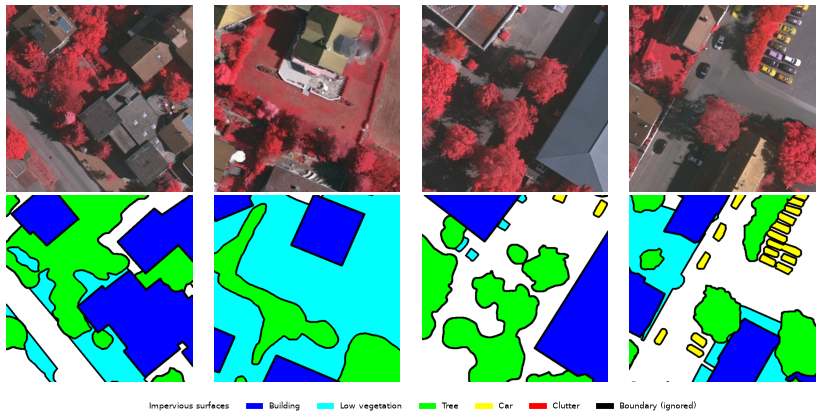

In [3]:
def colorize(lbl):
    out = np.zeros((*lbl.shape, 3), np.uint8)
    valid = lbl != IGNORE
    out[valid] = PALETTE[lbl[valid]]
    return out  # boundaries stay black

with plt.rc_context({"figure.dpi": 60}):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for k, i in enumerate([0, 40, 120, 200]):
        axes[0, k].imshow(tr_imgs[i]); axes[1, k].imshow(colorize(tr_lbls[i]))
    for ax in axes.flat: ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[c] / 255) for c in range(len(CLASSES))] + [plt.Rectangle((0, 0), 1, 1, color="black")]
    fig.legend(handles, CLASSES + ["Boundary (ignored)"], loc="lower center", ncol=7, frameon=False)
    plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

### Dataset and augmentation
- **Training** uses random 256×256 crops from the 512×512 tiles, with random flips and 90° rotations. Aerial images have no natural "up", so these are free extra data. Taking crops keeps full resolution: shrinking the whole tile to 256 would make cars, which are already small, four times smaller.
- **Evaluation** runs on the full 512×512 tiles. The U-Net is fully convolutional, so it accepts any size divisible by 16.
- Images are normalised with the training set's per-channel mean and standard deviation.

In [4]:
_px = tr_imgs[::5].reshape(-1, 3).astype(np.float32) / 255  # every 5th tile is plenty for channel statistics
MEAN, STD = _px.mean(0), _px.std(0)
del _px

class Tiles(Dataset):
    def __init__(self, imgs, lbls, crop=None, augment=False, samples=None):
        self.imgs, self.lbls, self.crop, self.augment = imgs, lbls, crop, augment
        self.samples = samples or len(imgs)

    def __len__(self):
        return self.samples

    def __getitem__(self, i):
        i = i % len(self.imgs)
        img, lbl = self.imgs[i], self.lbls[i]
        if self.crop:
            y, x = np.random.randint(0, img.shape[0] - self.crop + 1), np.random.randint(0, img.shape[1] - self.crop + 1)
            img, lbl = img[y:y + self.crop, x:x + self.crop], lbl[y:y + self.crop, x:x + self.crop]
        if self.augment:
            k = np.random.randint(4)
            img, lbl = np.rot90(img, k), np.rot90(lbl, k)
            if np.random.rand() < 0.5:
                img, lbl = img[:, ::-1], lbl[:, ::-1]
        x = (torch.from_numpy(np.ascontiguousarray(img)).float() / 255 - torch.tensor(MEAN).float()) / torch.tensor(STD).float()
        return x.permute(2, 0, 1), torch.from_numpy(np.ascontiguousarray(lbl)).long()

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(Tiles(tr_imgs, tr_lbls, crop=256, augment=True, samples=4 * len(tr_imgs)), batch_size=8, shuffle=True, generator=g)
val_loader = DataLoader(Tiles(va_imgs, va_lbls), batch_size=4)
test_loader = DataLoader(Tiles(test_imgs, test_lbls), batch_size=4)

## 3. Model: U-Net
This is the same U-Net as the first version (four encoder and decoder levels with skip connections, starting at 32 channels). The only change is that the final layer outputs **6 class logits** instead of one sigmoid channel.

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.enc1, self.enc2, self.enc3, self.enc4 = ConvBlock(3, 32), ConvBlock(32, 64), ConvBlock(64, 128), ConvBlock(128, 256)
        self.bottom = ConvBlock(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
        self.dec1, self.dec2 = ConvBlock(512 + 256, 256), ConvBlock(256 + 128, 128)
        self.dec3, self.dec4 = ConvBlock(128 + 64, 64), ConvBlock(64 + 32, 32)
        self.out = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        c1 = self.enc1(x); c2 = self.enc2(self.pool(c1)); c3 = self.enc3(self.pool(c2)); c4 = self.enc4(self.pool(c3))
        b = self.bottom(self.pool(c4))
        d = self.dec1(torch.cat([self.up(b), c4], 1))
        d = self.dec2(torch.cat([self.up(d), c3], 1))
        d = self.dec3(torch.cat([self.up(d), c2], 1))
        d = self.dec4(torch.cat([self.up(d), c1], 1))
        return self.out(d)  # logits; softmax is applied inside the loss / at prediction time


model = UNet(len(CLASSES)).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

7.9M parameters


## 4. Loss and metrics
- **Loss:** cross-entropy plus a multi-class *soft Dice* loss. Cross-entropy alone is dominated by the large classes. Dice weights each class equally, which helps rare ones such as cars. Boundary pixels are ignored in both terms.
- **Metrics:** a confusion matrix over all labelled pixels gives the per-class **IoU** (intersection over union) and **F1**, plus overall accuracy. Following common practice on Vaihingen, **mIoU and mean F1 are averaged over the five main classes**: clutter makes up under 0.1% of the training pixels and is reported separately.

In [6]:
def soft_dice_loss(logits, target, eps=1.0):
    valid = (target != IGNORE).unsqueeze(1)
    probs = logits.float().softmax(1) * valid
    onehot = F.one_hot(target.clamp(max=len(CLASSES) - 1), len(CLASSES)).permute(0, 3, 1, 2) * valid
    inter, total = (probs * onehot).sum((0, 2, 3)), (probs + onehot).sum((0, 2, 3))
    present = onehot.sum((0, 2, 3)) > 0  # average only over classes present in the batch
    return 1 - ((2 * inter + eps) / (total + eps))[present].mean()

ce = nn.CrossEntropyLoss(ignore_index=IGNORE)
loss_fn = lambda logits, target: ce(logits, target) + soft_dice_loss(logits, target)

@torch.no_grad()
def confusion(model, loader):
    model.eval()
    cm = torch.zeros(len(CLASSES), len(CLASSES), dtype=torch.long, device=DEVICE)
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            pred = model(x).argmax(1)
        valid = y != IGNORE
        cm += torch.bincount(y[valid] * len(CLASSES) + pred[valid], minlength=len(CLASSES) ** 2).view(len(CLASSES), -1)
    return cm.cpu().numpy()

def scores(cm, main=5):
    tp = np.diag(cm).astype(float)
    iou = tp / (cm.sum(0) + cm.sum(1) - tp + 1e-9)
    f1 = 2 * tp / (cm.sum(0) + cm.sum(1) + 1e-9)
    return {"OA": tp.sum() / cm.sum(), "mIoU": iou[:main].mean(), "mF1": f1[:main].mean(), "IoU": iou, "F1": f1}

## 5. Training
The model is trained for 60 epochs with Adam (learning rate 1e-3, cosine decay) and mixed precision. Each epoch draws 4 random crops per training tile. The checkpoint with the best **validation mIoU** is kept, and the test set is not used until section 6.

In [7]:
EPOCHS = 60
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))
scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
history, best, start = [], {"mIoU": -1}, time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            loss = loss_fn(model(x), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item()
    val = scores(confusion(model, val_loader))
    history.append({"epoch": epoch, "train loss": total / len(train_loader), "val mIoU": val["mIoU"], "val OA": val["OA"]})
    if val["mIoU"] > best["mIoU"]:
        best = {"mIoU": val["mIoU"], "epoch": epoch, "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:2d} | train loss {history[-1]['train loss']:.3f} | val OA {val['OA']:.3f} | val mIoU {val['mIoU']:.3f}")

model.load_state_dict(best["state"])
print(f"\nBest validation mIoU {best['mIoU']:.3f} at epoch {best['epoch']} ({(time.time() - start) / 60:.1f} min)")

epoch  1 | train loss 1.464 | val OA 0.715 | val mIoU 0.455


epoch  5 | train loss 0.992 | val OA 0.805 | val mIoU 0.585


epoch 10 | train loss 0.877 | val OA 0.814 | val mIoU 0.614


epoch 15 | train loss 0.811 | val OA 0.773 | val mIoU 0.560


epoch 20 | train loss 0.781 | val OA 0.838 | val mIoU 0.634


...

epoch 40 | train loss 0.620 | val OA 0.830 | val mIoU 0.644


epoch 45 | train loss 0.600 | val OA 0.823 | val mIoU 0.649


epoch 50 | train loss 0.539 | val OA 0.831 | val mIoU 0.657


epoch 55 | train loss 0.555 | val OA 0.815 | val mIoU 0.634


epoch 60 | train loss 0.551 | val OA 0.819 | val mIoU 0.642

Best validation mIoU 0.661 at epoch 30 (20.6 min)


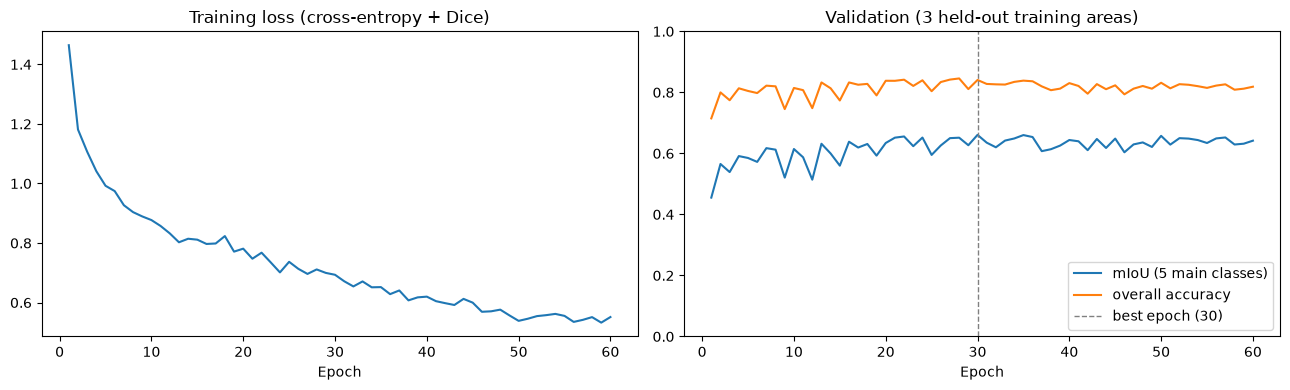

In [8]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(h["epoch"], h["train loss"]); axes[0].set(title="Training loss (cross-entropy + Dice)", xlabel="Epoch")
axes[1].plot(h["epoch"], h["val mIoU"], label="mIoU (5 main classes)"); axes[1].plot(h["epoch"], h["val OA"], label="overall accuracy")
axes[1].axvline(best["epoch"], color="grey", ls="--", lw=1, label=f"best epoch ({best['epoch']})")
axes[1].set(title="Validation (3 held-out training areas)", xlabel="Epoch", ylim=(0, 1)); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 6. Test results: 17 unseen areas (official `val` split, 398 tiles)

In [9]:
cm = confusion(model, test_loader)
test = scores(cm)
per_class = pd.DataFrame({"IoU": test["IoU"], "F1": test["F1"],
                          "Share of test pixels": cm.sum(1) / cm.sum()}, index=CLASSES)
majority = cm.sum(1).max() / cm.sum()
print(f"Overall accuracy: {test['OA']:.1%}  (always predicting the most common class: {majority:.1%})")
print(f"mIoU (5 main classes): {test['mIoU']:.3f} | mean F1 (5 main classes): {test['mF1']:.3f}")
per_class.style.format({"IoU": "{:.3f}", "F1": "{:.3f}", "Share of test pixels": "{:.1%}"})

Overall accuracy: 81.5%  (always predicting the most common class: 27.7%)
mIoU (5 main classes): 0.638 | mean F1 (5 main classes): 0.771


,IoU,F1,Share of test pixels
Impervious surfaces,0.729,0.844,27.7%
Building,0.723,0.839,26.3%
Low vegetation,0.619,0.765,21.8%
Tree,0.716,0.835,22.4%
Car,0.404,0.575,0.9%
Clutter,0.095,0.174,0.9%


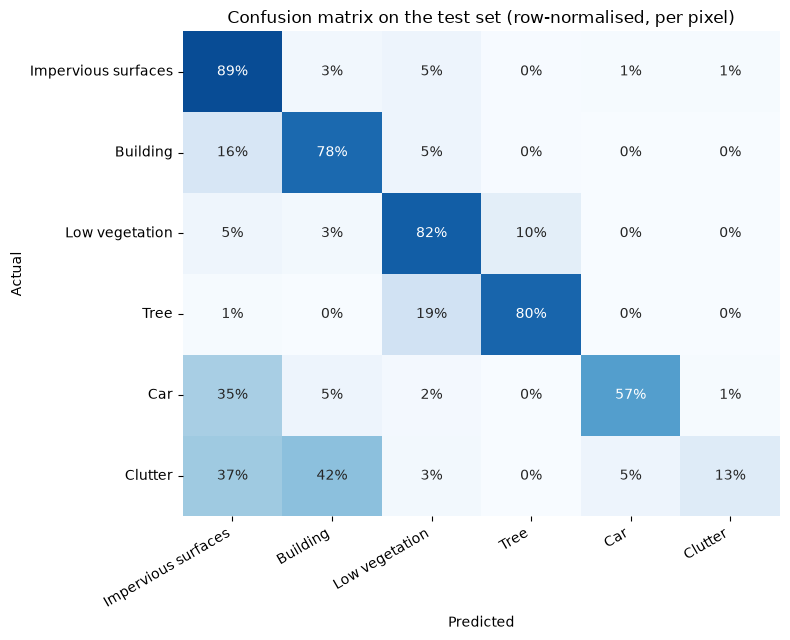

In [10]:
cm_norm = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(title="Confusion matrix on the test set (row-normalised, per pixel)", xlabel="Predicted", ylabel="Actual")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

### Example predictions on unseen test areas

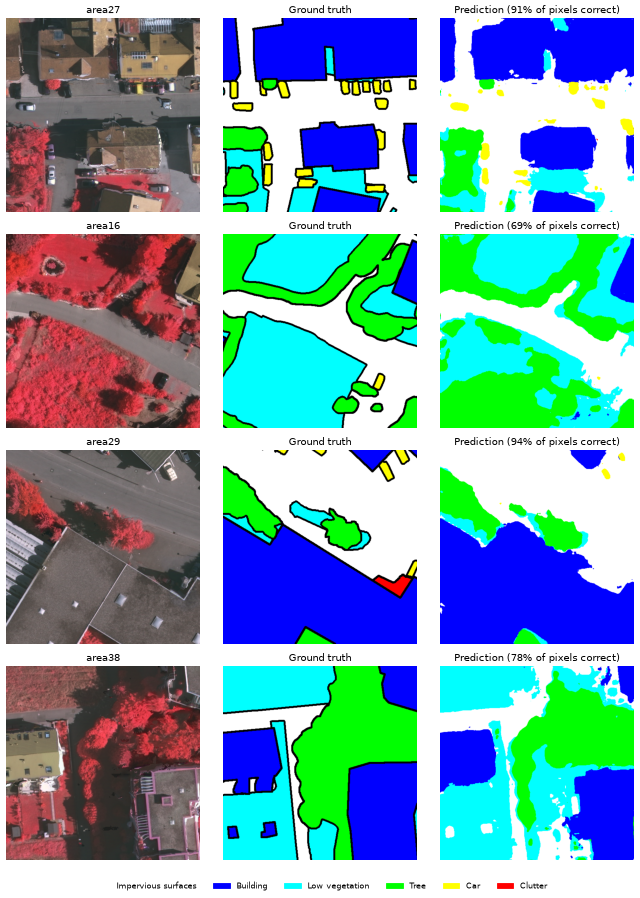

In [11]:
@torch.no_grad()
def predict_tile(img):
    x = (torch.from_numpy(img).float() / 255 - torch.tensor(MEAN).float()) / torch.tensor(STD).float()
    model.eval()
    with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
        return model(x.permute(2, 0, 1)[None].to(DEVICE)).argmax(1)[0].cpu().numpy()

rng = random.Random(7)
picks = rng.sample(range(len(test_imgs)), 4)
with plt.rc_context({"figure.dpi": 60}):
    fig, axes = plt.subplots(4, 3, figsize=(11, 15))
    for r, i in enumerate(picks):
        pred = predict_tile(test_imgs[i])
        valid = test_lbls[i] != IGNORE
        acc = (pred[valid] == test_lbls[i][valid]).mean()
        for ax, im, title in zip(axes[r], [test_imgs[i], colorize(test_lbls[i]), PALETTE[pred]],
                                 [test_names[i].split("_")[0], "Ground truth", f"Prediction ({acc:.0%} of pixels correct)"]):
            ax.imshow(im); ax.set_title(title); ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[c] / 255) for c in range(len(CLASSES))]
    fig.legend(handles, CLASSES, loc="lower center", ncol=6, frameon=False)
    plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

## 7. Takeaways

In [12]:
order = per_class["IoU"].iloc[:5].sort_values()
off = cm_norm.copy(); np.fill_diagonal(off, 0); a, b = np.unravel_index(off[:5, :5].argmax(), (5, 5))
print(f"Test overall accuracy : {test['OA']:.1%} (majority-class baseline {majority:.1%})")
print(f"Test mIoU / mean F1   : {test['mIoU']:.3f} / {test['mF1']:.3f} (5 main classes)")
print(f"Best / worst class    : {order.index[-1]} (IoU {order.iloc[-1]:.2f}) / {order.index[0]} (IoU {order.iloc[0]:.2f})")
print(f"Largest confusion     : {CLASSES[a]} -> {CLASSES[b]} ({off[a, b]:.0%} of {CLASSES[a]} pixels)")

Test overall accuracy : 81.5% (majority-class baseline 27.7%)
Test mIoU / mean F1   : 0.638 / 0.771 (5 main classes)
Best / worst class    : Impervious surfaces (IoU 0.73) / Car (IoU 0.40)
Largest confusion     : Car -> Impervious surfaces (35% of Car pixels)


- **The model now actually learns.** On 17 geographic areas it never saw, it labels **81.5%** of pixels correctly, against 27.7% for always predicting the most common class. Its mIoU is **0.638** and its mean F1 **0.771** over the five main classes. The first version scored a Dice of 0.000 on every epoch.
- **Large classes are segmented well:** impervious surfaces, buildings and trees each reach about 0.72 IoU. Low vegetation (0.62) is mostly confused with **trees**: 19% of tree pixels are predicted as low vegetation and 10% the other way round. Both are vegetation, and their height difference isn't visible in a 2D image.
- **16% of building pixels are predicted as impervious surface.** Seen from directly above, flat roofs look a lot like pavement.
- **Cars are the hardest main class (IoU 0.40).** 35% of car pixels are labelled as the road surface they sit on, because cars are small and their edges blur into the road. **Clutter** (0.8% of pixels) is barely learned (IoU 0.10).
- **For context:** published Vaihingen results reach about 90% overall accuracy using ImageNet-pretrained backbones, the elevation model (DSM) that comes with the benchmark, and much larger networks. This is a 7.9M-parameter U-Net trained from scratch in about 20 minutes on a laptop GPU. Validation mIoU stopped improving after about 30 epochs while the training loss kept falling.
- **Next steps:** a pretrained encoder (e.g. a ResNet-34 U-Net), adding the DSM as a fourth input channel, and test-time augmentation with flips and rotations.